# People You May Know: Friend & Page Recommender

A small recommendation engine in plain Python. It suggests **people you may know** (ranked by mutual friends) and **pages you might like** (from people with similar interests). It also cleans the data first and measures how well the suggestions actually work.

> **Credit:** the base idea and the dataset come from the *People You May Know* project in CodeWithHarry's Data Science course. On top of the course version I:
> - fixed data-quality bugs that made the original code crash or suggest deleted users,
> - made every suggestion explainable (names, mutual friends, reasons),
> - added a fallback for users who got no page suggestions,
> - built an offline evaluation (leave-one-out, Hit@k against a random baseline) and ran it on a real social network as well.

**Results at a glance** (Hit@3 = how often a hidden real friend shows up in the top 3 suggestions)

| Network | People You May Know | Random guess |
|---|---|---|
| Course dataset (30 users) | 15.8% | 12.2% |
| Real friendship network (34 people) | 39.1% | 12.0% |

**Contents**
1. Load the data
2. Clean the data
3. People You May Know
4. Pages You Might Like
5. Evaluation: does it actually work?
6. Conclusions

In [1]:
import csv
import json
import os
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter

## 1. Load the data

The course provides two JSON files:
- `data/messy_sample.json`: 5 users with problems such as a blank name, a duplicate friend and a duplicate page id. Used to test the cleaning step.
- `data/social_network.json`: the main dataset, 30 users and 27 pages.

Each user has an `id`, a `name`, a list of `friends` (user ids) and a list of `liked_pages` (page ids).

In [2]:
def load_data(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


messy = load_data("data/messy_sample.json")
network = load_data("data/social_network.json")

print("Messy sample:", len(messy["users"]), "users,", len(messy["pages"]), "pages")
print("Main dataset:", len(network["users"]), "users,", len(network["pages"]), "pages")
pd.DataFrame(network["users"]).head()

Messy sample: 5 users, 5 pages
Main dataset: 30 users, 27 pages


,id,name,friends,liked_pages
0,1,Amit,"[2, 3, 4, 5, 6]","[101, 102]"
1,2,Priya,"[1, 3, 5, 6, 7]","[102, 103]"
2,3,Rahul,"[1, 2, 4, 7, 8]","[101, 103]"
3,4,Sara,"[1, 3, 6, 8, 9]",[104]
4,5,Neha,"[1, 2, 6, 10, 11]","[102, 105]"


## 2. Clean the data

Before recommending anything, `clean_data()` does five things:
1. keeps only the first page when two pages share the same id,
2. removes users with a blank name, and users with no friends and no liked pages,
3. removes duplicate friends, self-friendship, and friend ids of users who are not in the data. The course version kept these, so the recommender **crashed** (`KeyError`) or **suggested users who had been deleted**,
4. makes every friendship two-way (if A lists B as a friend, B must list A),
5. removes liked page ids that don't exist.

It returns the users as a dictionary keyed by id (easy lookups), the pages as `{id: name}`, and a list of every fix it made, so nothing changes silently.

In [3]:
def clean_data(data):
    # Returns (users, pages, fixes). The input data is not modified.
    fixes = []

    # 1. Pages: keep the first page for each id
    pages = {}
    for page in data["pages"]:
        if page["id"] in pages:
            fixes.append(f"Page {page['id']}: duplicate id, kept '{pages[page['id']]}', dropped '{page['name']}'")
        else:
            pages[page["id"]] = page["name"]

    # 2. Users: drop users with no name, or with no friends and no liked pages
    users = {}
    for user in data["users"]:
        name = (user.get("name") or "").strip()
        if not name:
            fixes.append(f"User {user['id']}: removed (blank name)")
            continue
        if not user["friends"] and not user["liked_pages"]:
            fixes.append(f"{name} ({user['id']}): removed (no friends and no liked pages)")
            continue
        if len(set(user["friends"])) < len(user["friends"]):
            fixes.append(f"{name} ({user['id']}): removed duplicate friend ids")
        users[user["id"]] = {
            "name": name,
            "friends": set(user["friends"]),          # a set removes duplicates
            "liked_pages": set(user["liked_pages"]),
        }

    # 3. Keep only friends who exist (and are not the user themself), and pages that exist
    for user_id, user in users.items():
        valid_friends = {f for f in user["friends"] if f in users and f != user_id}
        removed = user["friends"] - valid_friends
        if removed:
            fixes.append(f"{user['name']} ({user_id}): removed friend ids {sorted(removed)} (not in the data)")
        user["friends"] = valid_friends

        valid_pages = {p for p in user["liked_pages"] if p in pages}
        removed = user["liked_pages"] - valid_pages
        if removed:
            fixes.append(f"{user['name']} ({user_id}): removed unknown page ids {sorted(removed)}")
        user["liked_pages"] = valid_pages

    # 4. Make every friendship two-way
    for user_id, user in users.items():
        for friend_id in sorted(user["friends"]):
            if user_id not in users[friend_id]["friends"]:
                users[friend_id]["friends"].add(user_id)
                fixes.append(
                    f"{user['name']} ({user_id}) lists {users[friend_id]['name']} ({friend_id}) as a friend, "
                    "but not the other way round: added the missing link"
                )

    return users, pages, fixes

**Test on the messy sample.** Every problem in the file is caught and reported:

In [4]:
sample_users, sample_pages, sample_fixes = clean_data(messy)
for fix in sample_fixes:
    print("-", fix)

- Page 104: duplicate id, kept 'Web Dev Hub', dropped 'Web Development'
- User 3: removed (blank name)
- Sara (4): removed duplicate friend ids
- Amit (5): removed (no friends and no liked pages)
- Amit (1): removed friend ids [3] (not in the data)


**Clean the main dataset.** It has no blank names or duplicates, but cleaning finds **8 one-way friendships**. For example, Nisha lists Amit as a friend, but Amit does not list Nisha.

In [5]:
users, pages, fixes = clean_data(network)
print(len(fixes), "fixes:")
for fix in fixes:
    print("-", fix)

friendships = sum(len(user["friends"]) for user in users.values()) // 2
print()
print(len(users), "users,", len(pages), "pages,", friendships, "friendships after cleaning")

8 fixes:
- Nisha (25) lists Amit (1) as a friend, but not the other way round: added the missing link
- Gautam (26) lists Rahul (3) as a friend, but not the other way round: added the missing link
- Kriti (27) lists Neha (5) as a friend, but not the other way round: added the missing link
- Harsh (28) lists Kunal (7) as a friend, but not the other way round: added the missing link
- Naveen (29) lists Ravi (9) as a friend, but not the other way round: added the missing link
- Naveen (29) lists Arjun (11) as a friend, but not the other way round: added the missing link
- Ishita (30) lists Kabir (13) as a friend, but not the other way round: added the missing link
- Ishita (30) lists Varun (15) as a friend, but not the other way round: added the missing link

30 users, 27 pages, 79 friendships after cleaning


## 3. People You May Know

**Idea (from the course):** if two people are not friends yet but share many friends, they probably know each other. For each friend of the user, look at *their* friends. Everyone found this way who is not already a friend becomes a candidate, and the score is the number of **mutual friends**.

**My additions:** each suggestion shows the name and *which* mutual friends it came from ("because you both know ..."), ties are broken by user id so the output is always the same, and `top_k` sets how many suggestions to return.

In [6]:
def people_you_may_know(user_id, users, top_k=3):
    # Suggest the people who share the most mutual friends with user_id.
    if user_id not in users:
        return []
    my_friends = users[user_id]["friends"]

    mutual = {}  # candidate id -> set of mutual friends
    for friend_id in my_friends:
        for candidate in users[friend_id]["friends"]:
            if candidate != user_id and candidate not in my_friends:
                if candidate not in mutual:
                    mutual[candidate] = set()
                mutual[candidate].add(friend_id)

    # Most mutual friends first; on a tie, the smaller id first
    ranked = sorted(mutual.items(), key=lambda item: (-len(item[1]), item[0]))

    suggestions = []
    for candidate, via in ranked[:top_k]:
        suggestions.append({
            "id": candidate,
            "name": users[candidate]["name"],
            "mutual_friends": len(via),
            "because_you_both_know": ", ".join(users[f]["name"] for f in sorted(via)),
        })
    return suggestions

In [7]:
print("Amit's friends:", [users[f]["name"] for f in sorted(users[1]["friends"])])
pd.DataFrame(people_you_may_know(1, users, top_k=5))

Amit's friends: ['Priya', 'Rahul', 'Sara', 'Neha', 'Vikram', 'Nisha']


,id,name,mutual_friends,because_you_both_know
0,7,Kunal,2,"Priya, Rahul"
1,8,Anjali,2,"Rahul, Sara"
2,26,Gautam,2,"Rahul, Nisha"
3,27,Kriti,2,"Neha, Nisha"
4,9,Ravi,1,Sara


**Check on the cleaned messy sample.** The course version crashed here with `KeyError: 3`, because user 3 had been removed but was still in Amit's friend list. Now it works, and the removed user is never suggested:

In [8]:
pd.DataFrame(people_you_may_know(1, sample_users))

,id,name,mutual_friends,because_you_both_know
0,4,Sara,1,Priya


## 4. Pages You Might Like

**Idea (from the course):** find the users who like at least one of the same pages as me. Every other page they like gets points equal to the number of pages we share, so more overlap means more similar taste. This is a simple form of **user-based collaborative filtering**.

**Problem I found:** the data is sparse. Each user likes only 1–2 pages and 13 of the 27 pages have a single fan, so **14 of the 30 users get no suggestion at all**.

**Fix:** when there are fewer than `top_k` suggestions, fill the rest with the **most popular pages** the user doesn't already like, and label why each page was suggested.

In [9]:
def page_popularity(users):
    # How many users like each page
    counts = Counter()
    for user in users.values():
        counts.update(user["liked_pages"])
    return counts


def pages_you_might_like(user_id, users, pages, top_k=3, use_fallback=True):
    # Suggest pages liked by users with similar taste; fill any gaps with popular pages.
    if user_id not in users:
        return []
    my_pages = users[user_id]["liked_pages"]

    scores = {}  # page id -> score
    for other_id, other in users.items():
        if other_id == user_id:
            continue
        shared = my_pages & other["liked_pages"]
        if not shared:
            continue
        for page in other["liked_pages"] - my_pages:
            scores[page] = scores.get(page, 0) + len(shared)

    ranked = sorted(scores.items(), key=lambda item: (-item[1], item[0]))
    suggestions = []
    for page, score in ranked[:top_k]:
        suggestions.append({"page_id": page, "page": pages[page], "score": score,
                            "reason": "liked by people with similar taste"})

    if use_fallback and len(suggestions) < top_k:
        already_suggested = {s["page_id"] for s in suggestions}
        popular = sorted(page_popularity(users).items(), key=lambda item: (-item[1], item[0]))
        for page, likes in popular:
            if len(suggestions) == top_k:
                break
            if page not in my_pages and page not in already_suggested:
                suggestions.append({"page_id": page, "page": pages[page], "score": 0,
                                    "reason": f"popular page ({likes} likes)"})
    return suggestions

In [10]:
print("Amit likes:", [pages[p] for p in sorted(users[1]["liked_pages"])])
pd.DataFrame(pages_you_might_like(1, users, pages))

Amit likes: ['Python Developers', 'Data Science Enthusiasts']


,page_id,page,score,reason
0,103,AI & ML Community,2,liked by people with similar taste
1,105,Blockchain Innovators,1,liked by people with similar taste
2,107,Cloud Computing Pros,1,liked by people with similar taste


Meera likes only *Tech Entrepreneurs*, and the one other person who likes it has no other pages, so collaborative filtering finds nothing. The fallback still gives her suggestions:

In [11]:
print("Meera likes:", [pages[p] for p in sorted(users[12]["liked_pages"])])
pd.DataFrame(pages_you_might_like(12, users, pages))

Meera likes: ['Tech Entrepreneurs']


,page_id,page,score,reason
0,101,Python Developers,0,popular page (3 likes)
1,102,Data Science Enthusiasts,0,popular page (3 likes)
2,103,AI & ML Community,0,popular page (3 likes)


In [12]:
without_fallback = sum(1 for uid in users if pages_you_might_like(uid, users, pages, use_fallback=False))
with_fallback = sum(1 for uid in users if pages_you_might_like(uid, users, pages))
print(f"Users with at least one page suggestion: {without_fallback}/{len(users)} without fallback, "
      f"{with_fallback}/{len(users)} with fallback")

Users with at least one page suggestion: 16/30 without fallback, 30/30 with fallback


## 5. Evaluation: does it actually work?

Output that *looks* reasonable is not proof. A standard offline test for friend suggestions is **leave-one-out**:
1. take one real friendship (A, B) and **hide** it,
2. ask the recommender for A's top-k suggestions,
3. count a **hit** if B is in the list.

Repeat this for every friendship, from both sides. **Hit@k** is the share of hidden friends that came back in the top k.

To know whether a number is good, compare it with a **random guess**: picking k people at random from everyone A is not friends with finds B with probability k / (number of candidates).

In [13]:
def hide_friendship(users, a, b):
    # A copy of users with the friendship a-b removed (the original stays unchanged).
    # Each user dict is copied, with a fresh copy of its friends set.
    copy = {uid: {**user, "friends": set(user["friends"])} for uid, user in users.items()}
    copy[a]["friends"].discard(b)
    copy[b]["friends"].discard(a)
    return copy


def evaluate_friend_suggestions(users, k):
    # Leave-one-out Hit@k for people_you_may_know, plus the random-guess baseline.
    tests = hits = 0
    random_hits = 0.0
    for a in users:
        for b in sorted(users[a]["friends"]):
            test_users = hide_friendship(users, a, b)
            suggested_ids = [s["id"] for s in people_you_may_know(a, test_users, top_k=k)]
            tests += 1
            if b in suggested_ids:
                hits += 1
            candidates = len(test_users) - 1 - len(test_users[a]["friends"])  # everyone except A and A's friends
            random_hits += min(k, candidates) / candidates
    return {"k": k, "tests": tests, "hit_rate": hits / tests, "random_hit_rate": random_hits / tests}


def as_table(results):
    return pd.DataFrame([{
        "k": r["k"],
        "tests": r["tests"],
        "Hit@k": f"{r['hit_rate']:.1%}",
        "random guess": f"{r['random_hit_rate']:.1%}",
        "times better than random": f"{r['hit_rate'] / r['random_hit_rate']:.2f}x",
    } for r in results])


course_results = [evaluate_friend_suggestions(users, k) for k in (1, 3, 5)]
as_table(course_results)

,k,tests,Hit@k,random guess,times better than random
0,1,158,8.2%,4.1%,2.03x
1,3,158,15.8%,12.2%,1.30x
2,5,158,17.7%,20.3%,0.88x


### Why is it so weak here?

At k = 3 it is only slightly better than random, and at k = 5 it is even *worse* than random. The method assumes that **friends of friends become friends** (called *triadic closure*, which real social networks show strongly). Let's test that assumption on the data: what share of friend pairs have at least one mutual friend, compared with pairs who are *not* friends?

In [14]:
def mutual_friend_share(users):
    # Share of friend pairs and of non-friend pairs that have at least one mutual friend.
    ids = sorted(users)
    friend_pairs = friend_pairs_with_mutual = 0
    other_pairs = other_pairs_with_mutual = 0
    for i, a in enumerate(ids):
        for b in ids[i + 1:]:
            has_mutual = len(users[a]["friends"] & users[b]["friends"]) > 0
            if b in users[a]["friends"]:
                friend_pairs += 1
                friend_pairs_with_mutual += has_mutual
            else:
                other_pairs += 1
                other_pairs_with_mutual += has_mutual
    return (f"friend pairs with a mutual friend: {friend_pairs_with_mutual}/{friend_pairs} "
            f"({friend_pairs_with_mutual / friend_pairs:.0%}); "
            f"non-friend pairs: {other_pairs_with_mutual}/{other_pairs} "
            f"({other_pairs_with_mutual / other_pairs:.0%})")


print("Course data ->", mutual_friend_share(users))

Course data -> friend pairs with a mutual friend: 22/79 (28%); non-friend pairs: 188/356 (53%)


In the course data, friends are *less* likely to share a mutual friend than people who are not friends. That is the opposite of real life. The dataset follows a regular, artificial pattern (it was made for teaching), so the recommender's core assumption does not hold. This is a property of the data, not a bug in the code. To check the code itself, the next step runs the same test on real data.

### Same test on a real friendship network

**Zachary's Karate Club** (W. W. Zachary, 1977) is a classic real social network: friendships between 34 members of a university karate club. It has 78 friendships, almost the same size as the course data (30 users, 79 friendships). `data/karate_club_edges.csv` was exported from NetworkX (`networkx.karate_club_graph()`), with members numbered 1–34.

In [15]:
def load_edge_list(path):
    # Build the same users dictionary from a CSV of friendships (one pair per row).
    users = {}
    with open(path, "r", encoding="utf-8", newline="") as f:
        for row in csv.DictReader(f):
            a, b = int(row["member_a"]), int(row["member_b"])
            for person in (a, b):
                if person not in users:
                    users[person] = {"name": f"Member {person}", "friends": set(), "liked_pages": set()}
            users[a]["friends"].add(b)
            users[b]["friends"].add(a)
    return users


karate = load_edge_list("data/karate_club_edges.csv")
print(len(karate), "members,", sum(len(u["friends"]) for u in karate.values()) // 2, "friendships")
print("Real network ->", mutual_friend_share(karate))

34 members, 78 friendships
Real network -> friend pairs with a mutual friend: 67/78 (86%); non-friend pairs: 265/483 (55%)


In [16]:
karate_results = [evaluate_friend_suggestions(karate, k) for k in (1, 3, 5)]
as_table(karate_results)

,k,tests,Hit@k,random guess,times better than random
0,1,156,23.1%,4.0%,5.76x
1,3,156,39.1%,12.0%,3.25x
2,5,156,48.7%,20.0%,2.43x


On real data, the same code finds the hidden friend in its top 3 suggestions **39.1%** of the time, against **12.0%** for a random guess (**3.25x** better).

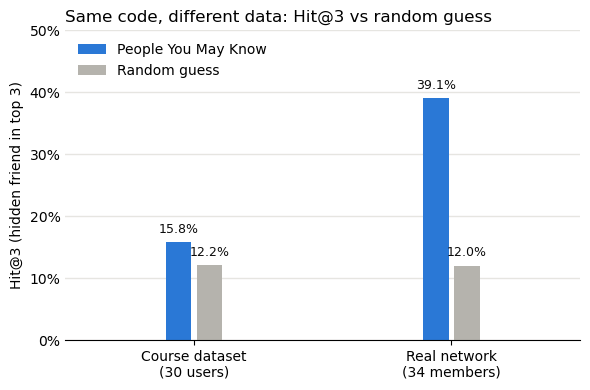

In [17]:
course_k3, karate_k3 = course_results[1], karate_results[1]  # index 1 -> k = 3
labels = ["Course dataset\n(30 users)", "Real network\n(34 members)"]
recommender = [course_k3["hit_rate"], karate_k3["hit_rate"]]
random_guess = [course_k3["random_hit_rate"], karate_k3["random_hit_rate"]]

fig, ax = plt.subplots(figsize=(6, 4))
positions = [0, 1]
width = 0.1
bars_model = ax.bar([p - 0.06 for p in positions], recommender, width, color="#2a78d6", label="People You May Know")
bars_random = ax.bar([p + 0.06 for p in positions], random_guess, width, color="#b5b3ad", label="Random guess")
for bar in list(bars_model) + list(bars_random):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01, f"{bar.get_height():.1%}",
            ha="center", va="bottom", fontsize=9, color="#0b0b0b")

ax.set_xticks(positions)
ax.set_xticklabels(labels)
ax.set_xlim(-0.5, 1.5)
ax.set_ylim(0, 0.5)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylabel("Hit@3 (hidden friend in top 3)")
ax.set_title("Same code, different data: Hit@3 vs random guess", loc="left")
ax.grid(axis="y", color="#e6e5e1", linewidth=1)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()

os.makedirs("images", exist_ok=True)
plt.savefig("images/hit_at_3.png", dpi=150, bbox_inches="tight")
plt.show()

### Page suggestions: leave-one-out on likes

Same idea for pages: for every user who likes at least 2 pages, hide one liked page and check whether it comes back in the top 3.

In [18]:
def evaluate_page_suggestions(users, pages, k=3, use_fallback=True):
    tests = hits = 0
    for uid in users:
        liked = users[uid]["liked_pages"]
        if len(liked) < 2:
            continue  # need at least one page left to find similar users
        for page in sorted(liked):
            test_users = {u: {**user, "liked_pages": set(user["liked_pages"])} for u, user in users.items()}
            test_users[uid]["liked_pages"].discard(page)
            suggested = [s["page_id"] for s in pages_you_might_like(uid, test_users, pages, top_k=k, use_fallback=use_fallback)]
            tests += 1
            if page in suggested:
                hits += 1
    return tests, hits


for fallback in (False, True):
    tests, hits = evaluate_page_suggestions(users, pages, use_fallback=fallback)
    print(f"Fallback {'on ' if fallback else 'off'}: {hits}/{tests} hidden pages found in the top 3 ({hits / tests:.1%})")

Fallback off: 0/28 hidden pages found in the top 3 (0.0%)
Fallback on : 6/28 hidden pages found in the top 3 (21.4%)


With similar-user scores alone, none of the 28 hidden pages came back, because the data is too sparse. The popularity fallback recovers 6 of 28 (21.4%) and gives every user at least one suggestion.

## 6. Conclusions

- **Cleaning matters.** The course data had a blank name, a duplicate friend, a duplicate page id and 8 one-way friendships. Left unhandled, these made the recommender crash or suggest deleted users.
- **Friend suggestions work when the data behaves like a real network.** On the real Karate Club network, mutual-friend ranking found the hidden friend in the top 3 **39.1%** of the time vs **12.0%** for a random guess (3.25x). On the course data it was barely better than random (15.8% vs 12.2%), because friends there rarely share friends (28% of friend pairs vs 53% of non-friend pairs).
- **Page suggestions suffer from sparse data.** Collaborative filtering alone left 14 of 30 users with nothing. A popularity fallback gave every user suggestions and recovered 21.4% of hidden likes, up from 0%.

**Limitations and next steps**
- Both networks are small (30–34 people), so a few hits move the numbers a lot. Next: test on a larger network such as the SNAP Facebook ego network (~4,000 users).
- Normalise the scores (Jaccard, Adamic–Adar) so that very well-connected users don't dominate.
- Combine signals, e.g. mutual friends + shared pages, into one score.